
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# Taylor Series

**Prerequisites:** [Taylor Polynomials and Taylor's Theorem](taylor-polynomials.ipynb#thm-lagrange-remainder) · [Infinite Series and Convergence Tests](series.ipynb) · [The Logarithm and the Exponential Function](exponential-and-logarithm.ipynb)

::: {#def-taylor-series}
## Taylor Series

If $f$ is infinitely differentiable at $a$, its **Taylor series** at $a$ is
$$\sum_{n=0}^\infty \frac{f^{(n)}(a)}{n!}(x - a)^n = f(a) + f'(a)(x - a) + \frac{f''(a)}{2!}(x-a)^2 + \cdots$$
Its partial sums are the Taylor polynomials $p_n$.
:::

Two questions: (a) for which $x$ does the series converge? (b) where it converges, is the sum $f(x)$? Since $f(x) - p_n(x) = R_n(x)$, the answer to both is yes at $x$ **if and only if** $R_n(x) \to 0$. The [Lagrange form](taylor-polynomials.ipynb#thm-lagrange-remainder) $R_n(x) = \frac{f^{(n+1)}(c)}{(n+1)!}(x - a)^{n+1}$ is the usual tool.

::: {#lem-factorial-dominates}
## $x^n/n! \to 0$

For every real $x$, $\frac{|x|^n}{n!} \to 0$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-factorial-dominates
Fix an integer $N \ge 2|x|$. For $n > N$, $\frac{|x|^n}{n!} = \frac{|x|^N}{N!}\cdot\frac{|x|}{N+1}\cdots\frac{|x|}{n} \le \frac{|x|^N}{N!}\Big(\frac12\Big)^{n - N} \to 0$. $\blacksquare$
:::

::: {#thm-elementary-taylor-series}
## Exponential, Sine, Cosine, Hyperbolic Functions

For every $x \in \mathbb{R}$:
$$e^x = \sum_{n=0}^\infty\frac{x^n}{n!}, \qquad \sin x = \sum_{k=0}^\infty\frac{(-1)^kx^{2k+1}}{(2k+1)!}, \qquad \cos x = \sum_{k=0}^\infty\frac{(-1)^kx^{2k}}{(2k)!},$$
$$\sinh x = \sum_{k=0}^\infty\frac{x^{2k+1}}{(2k+1)!}, \qquad \cosh x = \sum_{k=0}^\infty\frac{x^{2k}}{(2k)!}.$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-elementary-taylor-series
All derivatives of $e^x$ equal $e^x$, so the coefficients at $0$ are $\frac{1}{n!}$ and $|R_n(x)| = \frac{e^c|x|^{n+1}}{(n+1)!} \le e^{|x|}\frac{|x|^{n+1}}{(n+1)!} \to 0$ by @lem-factorial-dominates. The derivatives of $\sin, \cos$ at $0$ cycle through $0, 1, 0, -1$ resp. $1, 0, -1, 0$, and all derivatives are bounded by $1$, so $|R_n(x)| \le \frac{|x|^{n+1}}{(n+1)!} \to 0$. For $\sinh, \cosh$ the derivatives at $0$ alternate between $0$ and $1$, and all derivatives are bounded by $\cosh x \le e^{|x|}$ between $0$ and $x$. $\blacksquare$
:::

::: {#exm-taylor-series-cases}
## Other Behaviours

1. *Polynomials.* For $p$ of degree $k$, $p^{(n)} = 0$ for $n > k$; the Taylor series at any $a$ is $p$ itself, re-expanded in powers of $x - a$.
2. *Convergence on a smaller set than the domain.* For $f(x) = \frac1x$ at $a = 1$, the series $\sum_{n\ge0}(-1)^n(x - 1)^n$ is [geometric](geometric-sequence.ipynb#thm-geometric-series) with ratio $-(x - 1)$: it converges exactly for $0 < x < 2$, and there its sum is $\frac{1}{1 + (x - 1)} = \frac1x$. For $x \ge 2$ it diverges although $f$ is defined there.
3. *Convergent but to the wrong function.* Let $f(x) = e^{-1/x^2}$ for $x \ne 0$ and $f(0) = 0$. Then $f^{(n)}(0) = 0$ for all $n$, so the Taylor series at $0$ is identically $0$: it converges everywhere, but to $f$ only at $x = 0$.
:::

::: {#prp-flat-function}
## All Derivatives of $e^{-1/x^2}$ Vanish at $0$

For $f$ as in example 3, $f$ is infinitely differentiable on $\mathbb{R}$ and $f^{(n)}(0) = 0$ for all $n$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-flat-function
*Claim:* for $x \ne 0$, $f^{(n)}(x) = P_n\big(\frac1x\big)e^{-1/x^2}$ for a polynomial $P_n$. True for $n = 0$; if true for $n$, then $\big(P_n(\frac1x)e^{-1/x^2}\big)' = \big(-\frac{1}{x^2}P_n'(\frac1x) + \frac{2}{x^3}P_n(\frac1x)\big)e^{-1/x^2}$, again of this form.

*Derivatives at $0$:* if $f^{(n)}(0) = 0$, then $\frac{f^{(n)}(x) - f^{(n)}(0)}{x} = \frac1x P_n\big(\frac1x\big)e^{-1/x^2}$, a finite sum of terms $c\,t^m e^{-t^2}$ with $t = \frac1x \to \pm\infty$. Since $\frac{|t|^m}{e^{t^2}} \le \frac{|t|^m}{e^{|t|}} \to 0$ for $|t| \ge 1$ ([growth rates](exponential-and-logarithm.ipynb#prp-exp-log-limits)), $f^{(n+1)}(0) = 0$. $\blacksquare$
:::

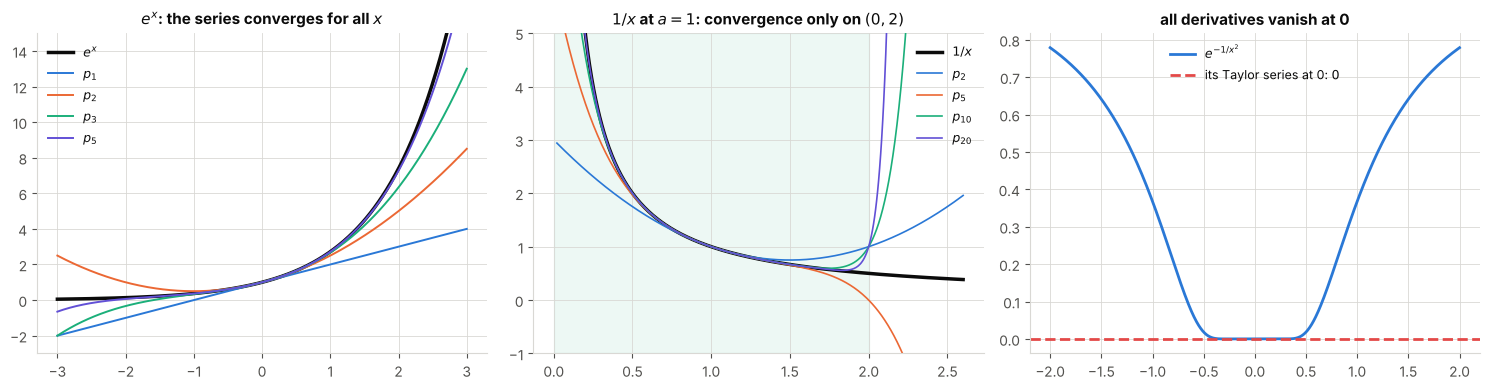

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from math import factorial

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
x = np.linspace(-3, 3, 400)
ax = axs[0]
ax.plot(x, np.exp(x), color=INK, lw=2.5, label="$e^x$")
for k, col in zip([1, 2, 3, 5], [BLUE, ORANGE, AQUA, VIOLET]):
    ax.plot(x, sum(x**j / factorial(j) for j in range(k + 1)), color=col, lw=1.4, label=f"$p_{k}$")
ax.set_ylim(-3, 15); ax.legend(fontsize=9); ax.set_title(r"$e^x$: the series converges for all $x$")

x = np.linspace(0.02, 2.6, 400)
ax = axs[1]
ax.plot(x, 1 / x, color=INK, lw=2.5, label="$1/x$")
for k, col in zip([2, 5, 10, 20], [BLUE, ORANGE, AQUA, VIOLET]):
    ax.plot(x, sum((-1)**j * (x - 1)**j for j in range(k + 1)), color=col, lw=1.2, label=f"$p_{{{k}}}$")
ax.axvspan(0, 2, color=AQUA, alpha=0.08); ax.set_ylim(-1, 5)
ax.legend(fontsize=9); ax.set_title(r"$1/x$ at $a = 1$: convergence only on $(0, 2)$")

x = np.linspace(-2, 2, 801)
with np.errstate(divide="ignore"):
    y = np.where(x == 0, 0.0, np.exp(-1 / x**2))
ax = axs[2]
ax.plot(x, y, color=BLUE, lw=2, label=r"$e^{-1/x^2}$")
ax.axhline(0, color=RED, lw=2, ls="--", label="its Taylor series at 0: $0$")
ax.legend(fontsize=9); ax.set_title("all derivatives vanish at 0")
plt.tight_layout(); plt.show()